# ms05 主成分与自相关（按配对）

对应 O'Shaughnessy et al., PRX Life **2**, 043006 (2024) Fig. 2 的做法，按配对单独做。
只用开发组。测试组的两个视频不读。

这次的划分是按视频指定的，不再按组：

| 开发 | 测试 |
|---|---|
| K_1_1, P_1_1, P_1_2, K_1_2 | K_1_3, P_1_3 |

K_1 的三天是同一三条鱼，P_1 的三天也是同一三条鱼。测试视频和开发视频是同一批动物的另一天，**测试组不是独立的**。这是指定的划分，不是按组留出。

之前的 S0–S11 是上一次划分（整个 K_1 做开发、整个 P_1 做测试）的结果，没有按这次划分重算。

## 步骤

1. 每对鱼 6 个点 × 3 个坐标 = 18 维。只用清洗、插值、平滑之后的连续片段，缺口处的帧丢掉，自相关不跨缺口。
2. 减去 6 个点的质心，绕 z 轴把「a 的胸鳍 → b 的胸鳍」的水平方向转到 +x。平移 3 个自由度和绕 z 的 1 个被去掉，剩下 14 维。
3. 对 14 维做 PCA，画累积方差。
4. 每个主成分的载荷画成姿态位移，并和 D、θ、弯曲角做相关，用来判断它更接近距离、朝向还是姿态。
5. 每个主成分先除以自身标准差（单位方差），再算自相关。相关时间是自相关第一次降到 1/e 的滞后。
6. 按相关时间从慢到快分组：相邻两个差 2 倍或以上就另起一组。这个倍数是起点，分组不必和论文的三组一样。
7. 每一组里，和 D、θ_a、θ_b、bend_a、bend_b 相关最高且 |r| ≥ 0.5 的那个量，作为这一组的代表量，供以后的转移矩阵选用。相关不够就留空，不硬指定。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*keyword-only.*")
warnings.filterwarnings("ignore", message=".*keyword-only.*")


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms05_pca_autocorr.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
WANTED = [
    ("20251225_K_1_1_FCMC", "dev"), ("20260112_P_1_1_FCMC", "dev"),
    ("20260113_P_1_2_FCMC", "dev"), ("20251225_K_1_2_FCMC", "dev"),
    ("20251225_K_1_3_FCMC", "test"), ("20260112_P_1_3_FCMC", "test"),
]
RULE = "manual 2026-11-06; K_1 and P_1 each have days on both sides, so the test days are not an independent group"
have = M.split_table()
same = "experiment" in have.columns and list(zip(have["experiment"], have["split"])) == WANTED
if not same:
    have = M.write_split(WANTED, RULE)
print(have.to_string(index=False))
for experiment, _ in WANTED[4:]:
    try:
        M.load_trial(experiment)
    except PermissionError as err:
        print("held out:", err)

         experiment group  day split                                                                                                       rule          created
20251225_K_1_1_FCMC   K_1    1   dev manual 2026-11-06; K_1 and P_1 each have days on both sides, so the test days are not an independent group 2026-11-06 14:36
20260112_P_1_1_FCMC   P_1    1   dev manual 2026-11-06; K_1 and P_1 each have days on both sides, so the test days are not an independent group 2026-11-06 14:36
20260113_P_1_2_FCMC   P_1    2   dev manual 2026-11-06; K_1 and P_1 each have days on both sides, so the test days are not an independent group 2026-11-06 14:36
20251225_K_1_2_FCMC   K_1    2   dev manual 2026-11-06; K_1 and P_1 each have days on both sides, so the test days are not an independent group 2026-11-06 14:36
20251225_K_1_3_FCMC   K_1    3  test manual 2026-11-06; K_1 and P_1 each have days on both sides, so the test days are not an independent group 2026-11-06 14:36
20260112_P_1_3_FCMC   P_1    3  te

In [3]:
PARAMS = M.load_params()
DEV = M.trials("dev")
print("dev:", DEV)
VIDEOS = []
for experiment in DEV:
    proc = M.process_trial(experiment, PARAMS)
    for pair in M.PAIR_NAMES:
        feat, valid = M.align_pair(M.pair_points(proc["nodes"], pair))
        valid &= proc["seg"] >= 0
        feat[~valid] = np.nan
        scalars = M.pose_scalars(proc["nodes"], pair)
        VIDEOS.append({"experiment": experiment, "pair": pair, "fps": proc["fps"], "seg": proc["seg"],
                       "feat": feat, "valid": valid, "scalars": scalars,
                       "n_valid": int(valid.sum()), "n_segments": int(len(np.unique(proc["seg"][valid])))})
    del proc
coverage = pd.DataFrame(VIDEOS)[["experiment", "pair", "n_valid", "n_segments"]]
coverage.to_csv(OUT / "S12_frame_coverage.csv", index=False)
coverage

dev: ['20251225_K_1_1_FCMC', '20260112_P_1_1_FCMC', '20260113_P_1_2_FCMC', '20251225_K_1_2_FCMC']


,experiment,pair,n_valid,n_segments
0,20251225_K_1_1_FCMC,F-M1,333088,19
1,20251225_K_1_1_FCMC,F-M2,331217,19
2,20251225_K_1_1_FCMC,M1-M2,330523,19
3,20260112_P_1_1_FCMC,F-M1,321043,8
4,20260112_P_1_1_FCMC,F-M2,323367,8
5,20260112_P_1_1_FCMC,M1-M2,325746,8
6,20260113_P_1_2_FCMC,F-M1,326434,16
7,20260113_P_1_2_FCMC,F-M2,328492,16
8,20260113_P_1_2_FCMC,M1-M2,331394,16
9,20251225_K_1_2_FCMC,F-M1,324627,21


F-M1: 1305192 frames, smallest eigenvalue 0.02083, components for 80% / 90%: 2 / 2


F-M2: 1306910 frames, smallest eigenvalue 0.02085, components for 80% / 90%: 2 / 2


M1-M2: 1311913 frames, smallest eigenvalue 0.02012, components for 80% / 90%: 2 / 2


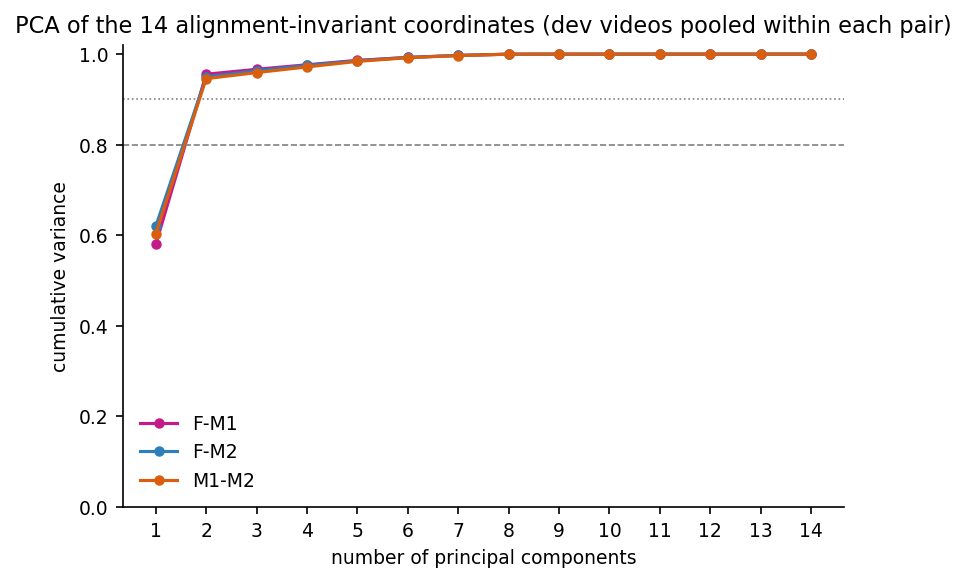

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S12_01_pca_cumulative_variance.png


In [4]:
MODELS, SCORES = {}, {}
for pair in M.PAIR_NAMES:
    rows = [v for v in VIDEOS if v["pair"] == pair]
    model = M.pca_fit(np.concatenate([v["feat"][v["valid"]] for v in rows]))
    MODELS[pair] = model
    for v in rows:
        SCORES[(v["experiment"], pair)] = M.pca_scores(v["feat"], model)
    cum = np.cumsum(model["variance_fraction"])
    print(f"{pair}: {model['n_frames']} frames, smallest eigenvalue {model['eigenvalues'][-1]:.4g}, "
          f"components for 80% / 90%: {int(np.searchsorted(cum, 0.8) + 1)} / {int(np.searchsorted(cum, 0.9) + 1)}")

fig, ax = plt.subplots(figsize=(6.2, 4))
for pair, color in zip(M.PAIR_NAMES, ("#c51b8a", "#2c7fb8", "#d95f0e")):
    frac = MODELS[pair]["variance_fraction"]
    ax.plot(np.arange(1, 15), np.cumsum(frac), "-o", ms=4, color=color, label=pair)
ax.axhline(0.8, color="0.5", ls="--", lw=0.8)
ax.axhline(0.9, color="0.5", ls=":", lw=0.8)
ax.set_xlabel("number of principal components")
ax.set_ylabel("cumulative variance")
ax.set_xticks(range(1, 15))
ax.set_ylim(0, 1.02)
ax.legend(frameon=False)
ax.set_title("PCA of the 14 alignment-invariant coordinates (dev videos pooled within each pair)")
show(fig, 12, 1, "pca_cumulative_variance")

载荷画的是平均姿态（实线）和沿该主成分移动两个标准差后的姿态（虚线），投影在水平面上。
颜色：品红是配对里的第一条鱼，蓝色是第二条。主要在竖直方向上的主成分在这张图里位移很小，要看下一张和俯仰角的相关。

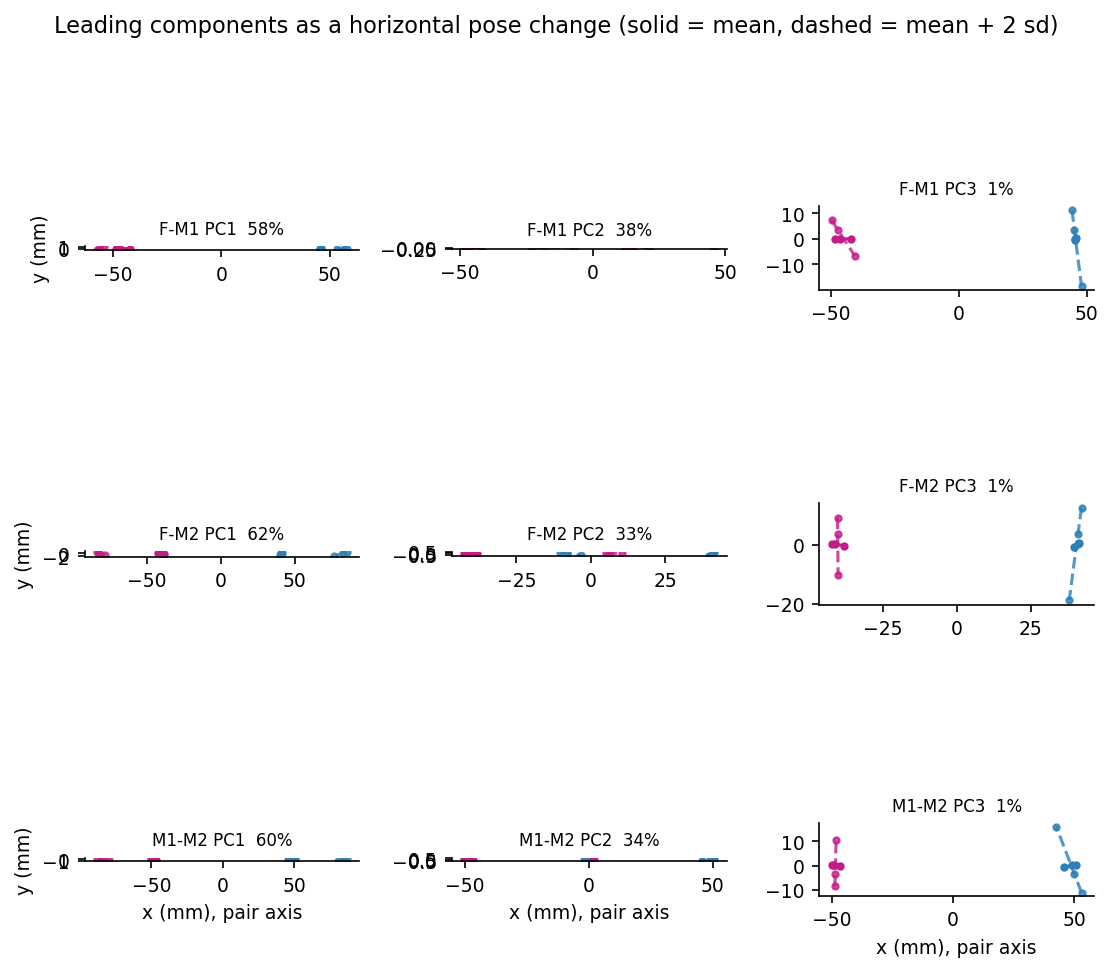

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S12_02_pca_mode_shapes.png


In [5]:
def show_count(frac):
    k = int(np.searchsorted(np.cumsum(frac), 0.80) + 1)
    return int(np.clip(k, 3, 5))


N_SHOW = max(show_count(MODELS[p]["variance_fraction"]) for p in M.PAIR_NAMES)
fig, axes = plt.subplots(len(M.PAIR_NAMES), N_SHOW, figsize=(2.5 * N_SHOW, 7.2))
for row, pair in enumerate(M.PAIR_NAMES):
    model = MODELS[pair]
    mean = M.reconstruct_pose(model["mean"][None])[0]
    disp = M.loadings_18(model).reshape(6, 3, -1)
    a, b = pair.split("-")
    for col in range(N_SHOW):
        ax = axes[row, col]
        scale = 2 * np.sqrt(max(model["eigenvalues"][col], 0))
        for idx, color, name in ((range(3), "#c51b8a", a), (range(3, 6), "#2c7fb8", b)):
            base = mean[list(idx)]
            moved = base + scale * disp[list(idx), :, col]
            ax.plot(base[:, 0], base[:, 1], "-o", ms=3, color=color, label=name if col == 0 and row == 0 else None)
            ax.plot(moved[:, 0], moved[:, 1], "--o", ms=3, color=color, alpha=0.8)
        ax.set_aspect("equal")
        ax.set_title(f"{pair} PC{col + 1}  {100 * model['variance_fraction'][col]:.0f}%", fontsize=8)
        if row == len(M.PAIR_NAMES) - 1:
            ax.set_xlabel("x (mm), pair axis")
        if col == 0:
            ax.set_ylabel("y (mm)")
fig.suptitle("Leading components as a horizontal pose change (solid = mean, dashed = mean + 2 sd)")
fig.tight_layout()
show(fig, 12, 2, "pca_mode_shapes")

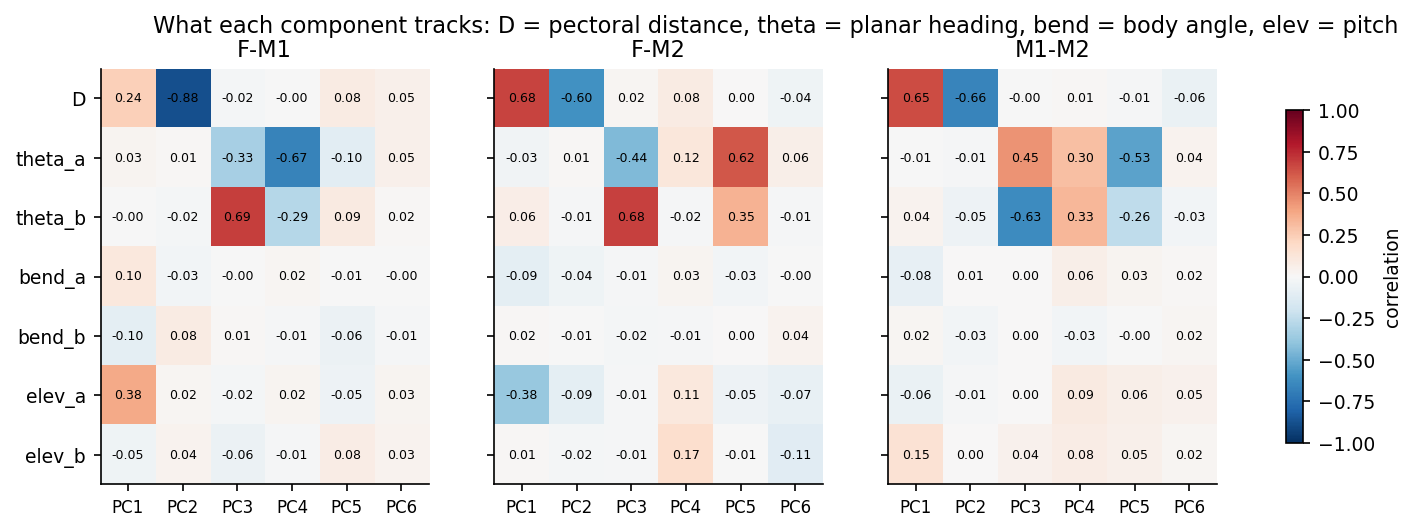

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S12_03_pca_loadings_vs_scalars.png


In [6]:
CORR = {}
for pair in M.PAIR_NAMES:
    blocks, segs, off = [], [], 0
    for v in [r for r in VIDEOS if r["pair"] == pair]:
        blocks.append(SCORES[(v["experiment"], pair)])
        seg = v["seg"].copy()
        ok = seg >= 0
        seg[ok] = seg[ok] + off
        off = int(seg[ok].max()) + 1
        segs.append(seg)
        if "scalars_cat" not in CORR:
            pass
    scores = np.concatenate(blocks)
    seg = np.concatenate(segs)
    scalars = {name: np.concatenate([v["scalars"][name] for v in VIDEOS if v["pair"] == pair]) for name in next(v["scalars"] for v in VIDEOS if v["pair"] == pair)}
    # concatenation order must match VIDEOS filter order; rebuild scalars in that same order
    rows = [r for r in VIDEOS if r["pair"] == pair]
    scalars = {name: np.concatenate([v["scalars"][name] for v in rows]) for name in rows[0]["scalars"]}
    CORR[pair] = M.correlate_modes(scores, scalars, seg)
    CORR[pair].insert(0, "pair", pair)
corr = pd.concat(CORR.values(), ignore_index=True)
corr.to_csv(OUT / "S12_mode_correlations.csv", index=False)

variables = ["D", "theta_a", "theta_b", "bend_a", "bend_b", "elev_a", "elev_b"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, pair in zip(axes, M.PAIR_NAMES):
    keep = list(range(1, 7))
    table = CORR[pair].pivot(index="variable", columns="component", values="r").loc[variables, keep]
    im = ax.imshow(table.values, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
    ax.set_xticks(range(len(keep)))
    ax.set_xticklabels([f"PC{c}" for c in keep], fontsize=8)
    ax.set_yticks(range(len(variables)))
    ax.set_yticklabels(variables)
    ax.set_title(pair)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation")
fig.suptitle("What each component tracks: D = pectoral distance, theta = planar heading, bend = body angle, elev = pitch")
show(fig, 12, 3, "pca_loadings_vs_scalars")

自相关只使用同一连续片段里的帧对。每条主成分先除以它自己的标准差。
相关时间取自相关第一次低于 1/e 的滞后。分组规则：把相关时间从大到小排，相邻之比 ≥ 2 就切开。

F-M1: 2 groups -> PC1+2 (11.83-22.25 s), PC4+5+3+8+6+7+14+13+12+11+9+10 (0.14-2.19 s)
F-M2: 3 groups -> PC1 (14.60-14.60 s), PC2 (6.29-6.29 s), PC3+4+5+6+8+7+14+13+11+12+9+10 (0.14-2.19 s)
M1-M2: 3 groups -> PC1+2 (4.13-7.77 s), PC3+4+5+6+7+8 (0.95-1.78 s), PC12+14+13+9+11+10 (0.14-0.33 s)


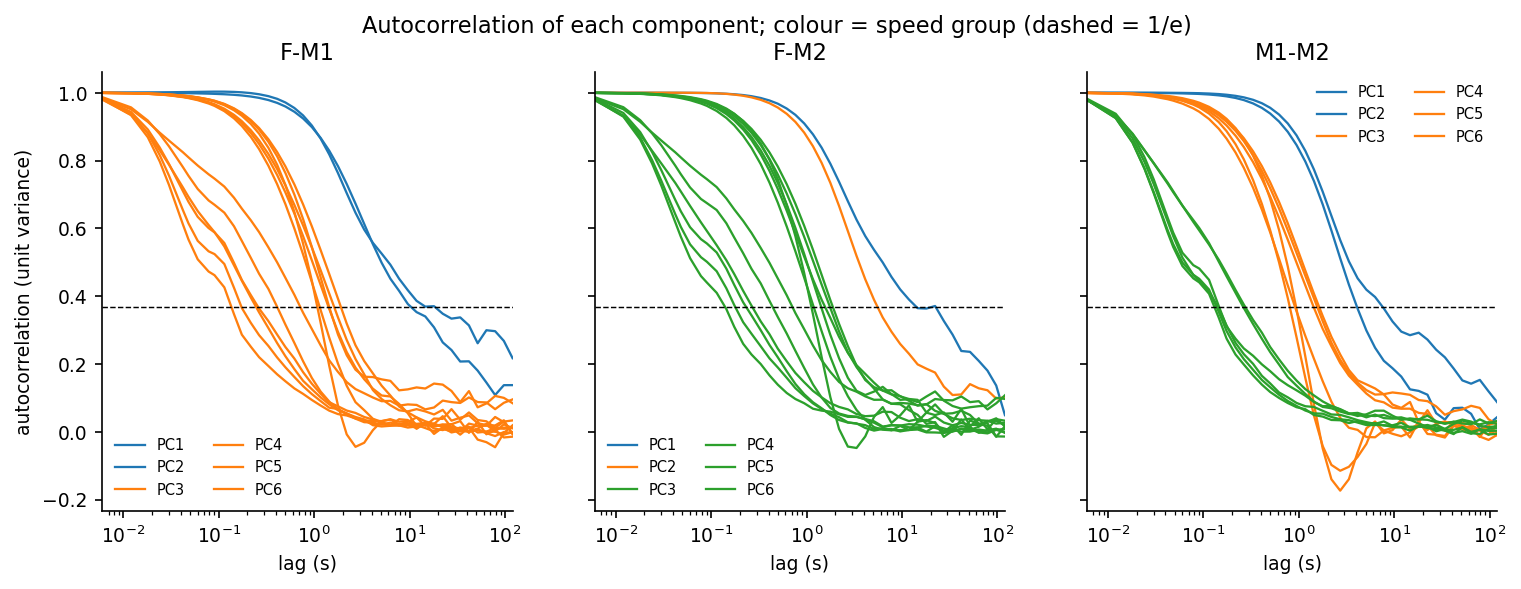

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S12_04_pca_autocorrelation.png


In [7]:
LAGS = np.unique(np.round(np.geomspace(1, 166 * 120, 48)).astype(int))
TIME_ROWS, CURVES = [], {}
for pair in M.PAIR_NAMES:
    rows = [r for r in VIDEOS if r["pair"] == pair]
    n_pc = SCORES[(rows[0]["experiment"], pair)].shape[1]
    pooled_score, pooled_seg, off = [], [], 0
    per_video = np.full((len(rows), n_pc), np.nan)
    for j, v in enumerate(rows):
        seg = v["seg"].copy()
        ok = seg >= 0
        seg[ok] = seg[ok] + off
        off = int(seg[ok].max()) + 1
        score = SCORES[(v["experiment"], pair)]
        pooled_score.append(score)
        pooled_seg.append(seg)
        for k in range(n_pc):
            tau, _ = M.correlation_time_s(score[:, k], v["seg"], v["fps"], LAGS)
            per_video[j, k] = tau
            TIME_ROWS.append({"pair": pair, "experiment": v["experiment"], "component": k + 1, "tau_s": tau, "scope": "video"})
    score = np.concatenate(pooled_score)
    seg = np.concatenate(pooled_seg)
    curves = []
    for k in range(n_pc):
        tau, curve = M.correlation_time_s(score[:, k], seg, rows[0]["fps"], LAGS)
        curves.append(curve)
        TIME_ROWS.append({"pair": pair, "experiment": "pooled", "component": k + 1, "tau_s": tau, "scope": "pooled"})
    CURVES[pair] = np.vstack(curves)
    CURVES[(pair, "per_video")] = per_video
times = pd.DataFrame(TIME_ROWS)
times.to_csv(OUT / "S12_correlation_times.csv", index=False)

GROUPS = {}
for pair in M.PAIR_NAMES:
    tau = times.query("pair == @pair and scope == 'pooled'").sort_values("component")["tau_s"].to_numpy()
    GROUPS[pair] = M.speed_groups(tau, min_ratio=2.0)
    text = ", ".join("PC" + "+".join(str(i + 1) for i in g) + f" ({tau[g].min():.2f}-{tau[g].max():.2f} s)" for g in GROUPS[pair])
    print(f"{pair}: {len(GROUPS[pair])} groups -> {text}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, pair in zip(axes, M.PAIR_NAMES):
    group_of = {i: g for g, members in enumerate(GROUPS[pair]) for i in members}
    for k, curve in enumerate(CURVES[pair]):
        ax.semilogx(LAGS / 166, curve, color=plt.cm.tab10(group_of.get(k, 9)), lw=1.1, label=f"PC{k + 1}" if k < 6 else None)
    ax.axhline(1 / np.e, color="k", ls="--", lw=0.7)
    ax.set_title(pair)
    ax.set_xlabel("lag (s)")
    ax.set_xlim(1 / 166, 120)
    ax.legend(frameon=False, fontsize=7, ncol=2)
axes[0].set_ylabel("autocorrelation (unit variance)")
fig.suptitle("Autocorrelation of each component; colour = speed group (dashed = 1/e)")
show(fig, 12, 4, "pca_autocorrelation")

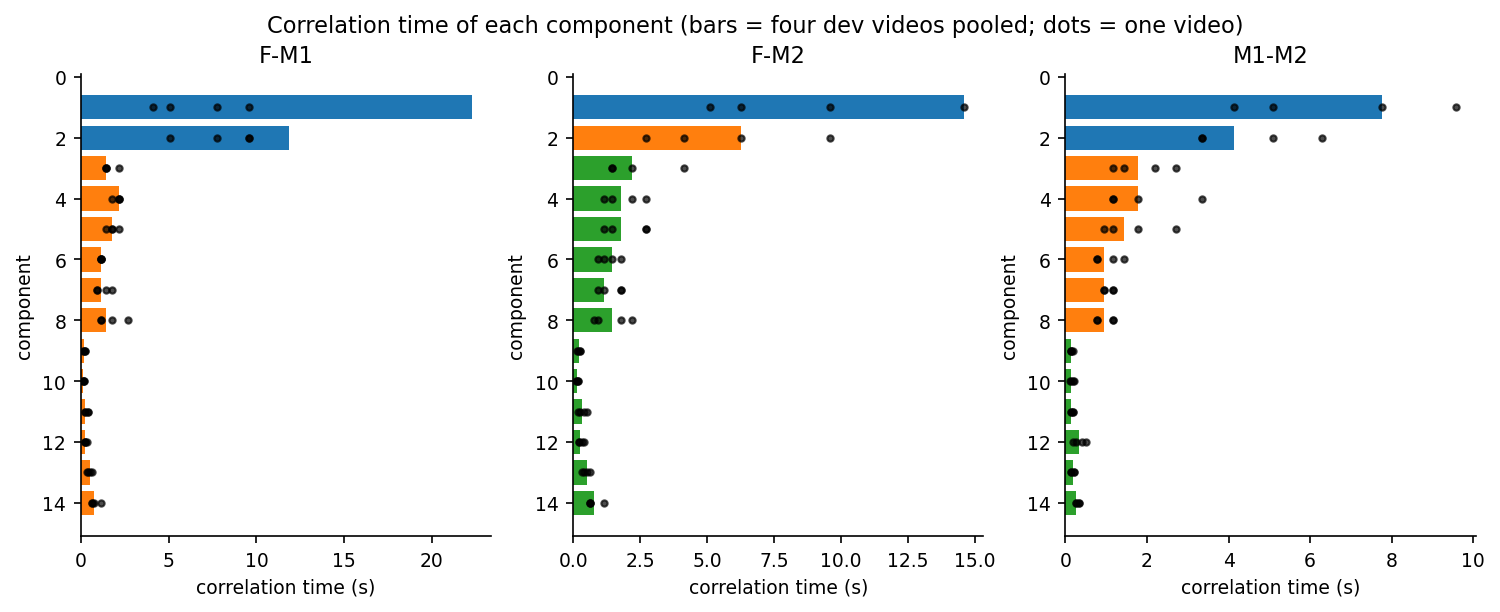

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S12_05_pca_correlation_times.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=False)
for ax, pair in zip(axes, M.PAIR_NAMES):
    pooled = times.query("pair == @pair and scope == 'pooled'").sort_values("component")
    tau = pooled["tau_s"].to_numpy()
    group_of = {i: g for g, members in enumerate(GROUPS[pair]) for i in members}
    colors = [plt.cm.tab10(group_of.get(i, 9)) for i in range(len(tau))]
    ax.barh(np.arange(len(tau)) + 1, tau, color=colors)
    per = CURVES[(pair, "per_video")]
    for j in range(per.shape[0]):
        ax.plot(per[j], np.arange(len(tau)) + 1, "o", ms=3, color="k", alpha=0.7)
    ax.set_xlabel("correlation time (s)")
    ax.set_ylabel("component")
    ax.set_title(pair)
    ax.invert_yaxis()
fig.suptitle("Correlation time of each component (bars = four dev videos pooled; dots = one video)")
show(fig, 12, 5, "pca_correlation_times")

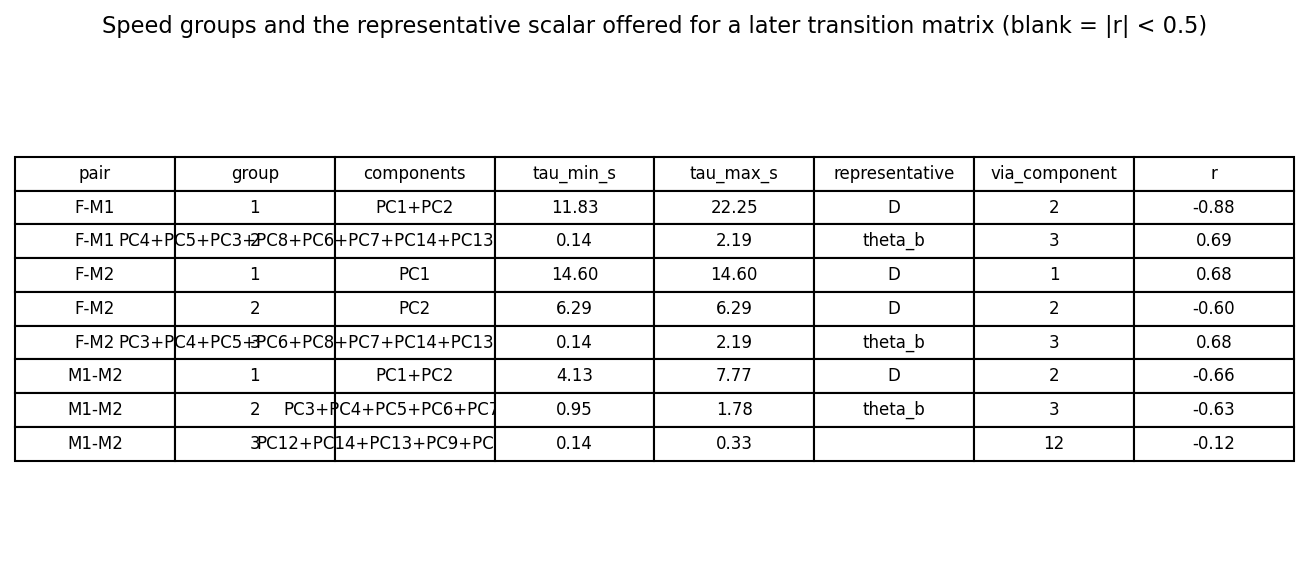

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S12_06_pca_speed_groups.png


,pair,group,slowest_first,components,tau_min_s,tau_max_s,representative,via_component,r,strongest_variable,strongest_r
0,F-M1,1,True,PC1+PC2,11.831325,22.253012,D,2,-0.877761,D,-0.877761
1,F-M1,2,False,PC4+PC5+PC3+PC8+PC6+PC7+PC14+PC13+PC12+PC11+PC...,0.144578,2.192771,theta_b,3,0.693806,theta_b,0.693806
2,F-M2,1,True,PC1,14.602410,14.602410,D,1,0.678929,D,0.678929
3,F-M2,2,False,PC2,6.289157,6.289157,D,2,-0.603705,D,-0.603705
4,F-M2,3,False,PC3+PC4+PC5+PC6+PC8+PC7+PC14+PC13+PC11+PC12+PC...,0.144578,2.192771,theta_b,3,0.683450,theta_b,0.683450
5,M1-M2,1,True,PC1+PC2,4.126506,7.765060,D,2,-0.661532,D,-0.661532
6,M1-M2,2,False,PC3+PC4+PC5+PC6+PC7+PC8,0.945783,1.777108,theta_b,3,-0.629463,theta_b,-0.629463
7,M1-M2,3,False,PC12+PC14+PC13+PC9+PC11+PC10,0.144578,0.331325,,12,-0.123803,bend_b,-0.123803


In [9]:
rows = []
for pair in M.PAIR_NAMES:
    tau = times.query("pair == @pair and scope == 'pooled'").sort_values("component")["tau_s"].to_numpy()
    for rank, members in enumerate(GROUPS[pair], start=1):
        pick = M.representative_of(members, CORR[pair])
        best = CORR[pair][CORR[pair]["component"].isin([i + 1 for i in members]) & CORR[pair]["variable"].isin(M.SCALAR_CANDIDATES)]
        top = best.loc[best["r"].abs().idxmax()] if len(best) else None
        rows.append({"pair": pair, "group": rank, "slowest_first": rank == 1,
                     "components": "+".join(f"PC{i + 1}" for i in members),
                     "tau_min_s": float(np.min(tau[members])), "tau_max_s": float(np.max(tau[members])),
                     "representative": pick["variable"] or "", "via_component": pick["component"] or "",
                     "r": pick["r"] if pick["r"] is not None else np.nan,
                     "strongest_variable": None if top is None else top["variable"],
                     "strongest_r": np.nan if top is None else float(top["r"])})
reps = pd.DataFrame(rows)
reps.to_csv(OUT / "S12_representatives.csv", index=False)
M.update_params("stage12", {"split": WANTED, "min_speed_ratio": 2.0, "representative_min_abs_r": 0.5,
                            "reference_direction": "horizontal pectoral(a) to pectoral(b), rotated onto +x",
                            "groups": reps.to_dict("records")})

show_df = reps[["pair", "group", "components", "tau_min_s", "tau_max_s", "representative", "via_component", "r"]].copy()
for col in ("tau_min_s", "tau_max_s", "r"):
    show_df[col] = show_df[col].map(lambda v: "" if pd.isna(v) else f"{v:.2f}")
fig, ax = plt.subplots(figsize=(11, 0.42 * len(show_df) + 1.2))
ax.axis("off")
table = ax.table(cellText=show_df.values, colLabels=list(show_df.columns), loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.35)
ax.set_title("Speed groups and the representative scalar offered for a later transition matrix (blank = |r| < 0.5)")
show(fig, 12, 6, "pca_speed_groups")
reps